Ok essayons de faire marcher git ce matin !
Je vais essayer de récupérer les données des prix de l'immobilier sur Paris à partir d'une url puis de les copier dans un nouveau csv dans notre projet.


# Import des Packages   

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

np.random.seed(123) 

# Récupération des données

C'était fastidieux mais j'ai réussi à trouver l'url )))

In [7]:
url = 'https://static.data.gouv.fr/resources/prix-immobilier-par-commune-ventes-2014-a-2025-dvf-millesime-2026/20261026-112727/prix-immobilier-communes-series-2014-2025.csv'
response = requests.get(url)
if response.status_code == 200:
    with open("data_immo_price.csv", "wb") as file:
        file.write(response.content)

# nétoyage des données

In [8]:
df = pd.read_csv("data_immo_price.csv")
df.head(20)

,code_insee,commune,code_departement,departement,region,population,annee,prix_m2_median,prix_m2_median_appartement,prix_m2_median_maison,prix_m2_median_neuf,ventes,ventes_maisons,ventes_appartements,source
0,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2014,1840.0,1994.0,1672.0,2684.0,139,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
1,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2015,1824.0,1734.0,1873.0,2677.0,166,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
2,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2018,1855.0,1667.0,1992.0,2398.0,206,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
3,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2019,2068.0,1925.0,2133.0,2345.0,214,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
4,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2020,1975.0,2012.0,1894.0,878.0,227,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
5,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2021,2189.0,2097.0,2324.0,3546.0,271,151.0,119.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
6,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2022,2419.0,2075.0,2630.0,3528.0,229,130.0,97.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
7,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2023,2322.0,2119.0,2646.0,3634.0,181,93.0,87.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
8,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2024,2276.0,2157.0,2377.0,3822.0,144,75.0,69.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
9,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2025,2485.0,2500.0,2333.0,3722.0,210,95.0,115.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."


In [9]:
df.axes

[RangeIndex(start=0, stop=61327, step=1),
 Index(['code_insee', 'commune', 'code_departement', 'departement', 'region',
        'population', 'annee', 'prix_m2_median', 'prix_m2_median_appartement',
        'prix_m2_median_maison', 'prix_m2_median_neuf', 'ventes',
        'ventes_maisons', 'ventes_appartements', 'source'],
       dtype='str')]

In [10]:
df.shape

(61327, 15)

bon à priori il n'y a que 5208 communes dans le jeu de données. Voyons si on en a un bon paquet en région Parisienne.

In [11]:
df['commune'].nunique()

5208

In [12]:
df['region'].unique()

<ArrowStringArray>
[      'Auvergne-Rhône-Alpes',            'Hauts-de-France',
 'Provence-Alpes-Côte d'Azur',                  'Grand Est',
                  'Occitanie',                  'Normandie',
         'Nouvelle-Aquitaine',        'Centre-Val de Loire',
    'Bourgogne-Franche-Comté',                   'Bretagne',
                      'Corse',           'Pays de la Loire',
              'Île-de-France',                 'Guadeloupe',
                 'Martinique',                     'Guyane',
                 'La Réunion']
Length: 17, dtype: str

L'INSEE ressence 1266 communes en Île de France en 2026, on en a ici 573, soit environ la moitié.

In [13]:
df[df['region'] == 'Île-de-France']['commune'].nunique()

573

In [14]:
df[df['region'] == 'Île-de-France']

,code_insee,commune,code_departement,departement,region,population,annee,prix_m2_median,prix_m2_median_appartement,prix_m2_median_maison,prix_m2_median_neuf,ventes,ventes_maisons,ventes_appartements,source
46358,75101,Paris 1er,75,Paris,Île-de-France,NaN,2021,12970.0,12970.0,NaN,NaN,309,0.0,309.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
46359,75101,Paris 1er,75,Paris,Île-de-France,NaN,2022,12936.0,12936.0,NaN,NaN,398,0.0,398.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
46360,75101,Paris 1er,75,Paris,Île-de-France,NaN,2023,12953.0,12953.0,NaN,NaN,345,0.0,345.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
46361,75101,Paris 1er,75,Paris,Île-de-France,NaN,2024,12586.0,12586.0,NaN,NaN,270,0.0,270.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
46362,75101,Paris 1er,75,Paris,Île-de-France,NaN,2025,12098.0,12098.0,NaN,NaN,291,0.0,291.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60268,95680,Villiers-le-Bel,95,Val-d'Oise,Île-de-France,30053.0,2021,2318.0,2164.0,2836.0,3278.0,199,70.0,129.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
60269,95680,Villiers-le-Bel,95,Val-d'Oise,Île-de-France,30053.0,2022,2517.0,2290.0,3206.0,3925.0,216,67.0,149.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
60270,95680,Villiers-le-Bel,95,Val-d'Oise,Île-de-France,30053.0,2023,2322.0,2186.0,3265.0,4024.0,155,51.0,103.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
60271,95680,Villiers-le-Bel,95,Val-d'Oise,Île-de-France,30053.0,2024,2278.0,2091.0,3066.0,3850.0,140,40.0,100.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."


In [15]:
df.loc[:,['region']]

df.drop_duplicates(subset = 'commune', keep = 'first')
df['code_insee'].isna().sum()
df2 = df.dropna()
df2.size - df.size


-843930

In [36]:
df3 = df.copy()
#df3[['population' + '_log']] = np.log(df.loc[:,['population']])
df3.assign(
    pop_log = np.log(pd.col('population'))
)
df3 = df3.drop(columns = ['population', 'prix_m2_median_appartement','prix_m2_median_maison','prix_m2_median_neuf','ventes', 'ventes_maisons', 'ventes_appartements','source'])

df_annee = {}

for i in df3['annee'].unique():
    df_annee[i] = df3[(df3['annee'] == i) # & (df3['region'] == 'Île-de-France' )
    ]
    df_annee[i].drop(columns = 'annee', inplace = True)
    df_annee[i].sort_values(['prix_m2_median'],inplace = True, ascending = False)
    df_annee[i].reset_index(inplace = True)
    
df_annee[2023].head(50)


/tmp/ipykernel_34254/2208837783.py:13: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_annee[i].drop(columns = 'annee', inplace = True)
/tmp/ipykernel_34254/2208837783.py:14: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_annee[i].sort_values(['prix_m2_median'],inplace = True, ascending = False)
/tmp/ipykernel_34254/2208837783.py:15: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_annee[i].reset_index(inplace = True)
/tmp/ipykernel_34254/2208837783.py:13: Pandas

,index,code_insee,commune,code_departement,departement,region,prix_m2_median
0,46385,75106,Paris 6e,75,Paris,Île-de-France,15000.0
1,46390,75107,Paris 7e,75,Paris,Île-de-France,14706.0
2,46375,75104,Paris 4e,75,Paris,Île-de-France,13103.0
3,46360,75101,Paris 1er,75,Paris,Île-de-France,12953.0
4,46395,75108,Paris 8e,75,Paris,Île-de-France,12768.0
5,46370,75103,Paris 3e,75,Paris,Île-de-France,12290.0
6,46380,75105,Paris 5e,75,Paris,Île-de-France,12093.0
7,52761,83119,Saint-Tropez,83,Var,Provence-Alpes-Côte d'Azur,11727.0
8,17605,33236,Lège-Cap-Ferret,33,Gironde,Nouvelle-Aquitaine,11668.0
9,46365,75102,Paris 2e,75,Paris,Île-de-France,11660.0


Voyons quelles sont les communes manquantes.

In [17]:
import io
import zipfile
import seaborn as sns

url_pop = f"https://www.data.gouv.fr/api/1/datasets/r/27361ae9-dcab-4312-97a1-48dab5f39218"
r = requests.get(url_pop)
z = zipfile.ZipFile(io.BytesIO(r.content))
print(z.namelist())   # les fichiers du zip

BadZipFile: File is not a zip file

In [ ]:
#le fichier que nous souhaitons avoir est celui qui ne contient pas les metadata
fichier_data_pop = [n for n in z.namelist() if "metadata" not in n][0]

#on ouvre le zip
with z.open(fichier_data_pop) as f:
    pop = pd.read_csv(f, sep=";", dtype=str)

print(pop.shape)
print(pop.columns.tolist())
pop.head()

(813234, 6)
['FREQ', 'GEO', 'GEO_OBJECT', 'POPREF_MEASURE', 'TIME_PERIOD', 'OBS_VALUE']


,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
0,A,15113,COM,PMUN,2010,197
1,A,14491,COM,PMUN,2007,154
2,A,14761,COM,PMUN,2011,746
3,A,14700,COM,PMUN,2018,663
4,A,15038,COM,PMUN,2013,1040


In [ ]:
pop_com = pop[(pop["POPREF_MEASURE"] == "PMUN") & (pop["GEO_OBJECT"].isin(["COM", "ARM"]))].copy()
pop_com

,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
0,A,15113,COM,PMUN,2010,197
1,A,14491,COM,PMUN,2007,154
2,A,14761,COM,PMUN,2011,746
3,A,14700,COM,PMUN,2018,663
4,A,15038,COM,PMUN,2013,1040
...,...,...,...,...,...,...
813229,A,16193,COM,PMUN,2015,1016
813230,A,15262,COM,PMUN,2014,534
813231,A,15260,COM,PMUN,2018,110
813232,A,15021,COM,PMUN,2023,665


In [ ]:
pop_com['TIME_PERIOD'].sort_values().unique()

pop_com['TIME_PERIOD'] = pd.to_numeric(pop_com['TIME_PERIOD'], errors='coerce').astype('Int64')
pop_com['OBS_VALUE'] = pd.to_numeric(pop_com['OBS_VALUE'], errors='coerce').astype('Int64')

pop_com = pop_com[pop_com['TIME_PERIOD'] >= 2014]

In [ ]:
pop_com

,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
3,A,14700,COM,PMUN,2018,663
5,A,15038,COM,PMUN,2015,1059
10,A,16270,COM,PMUN,2019,344
11,A,14543,COM,PMUN,2017,2438
13,A,15228,COM,PMUN,2022,461
...,...,...,...,...,...,...
813225,A,14528,COM,PMUN,2018,383
813229,A,16193,COM,PMUN,2015,1016
813231,A,15260,COM,PMUN,2018,110
813232,A,15021,COM,PMUN,2023,665


In [ ]:
pop_wide = pop_com.pivot(
    index = 'GEO',
    columns = 'TIME_PERIOD',
    values = 'OBS_VALUE'
)
pop_wide = pop_wide.reset_index().rename(columns={'GEO': 'code_insee'})

pop_per_year = []
Years = [y for y in pop_wide.columns if y != 'code_insee']
for year in Years:
    pop_per_year.append(pop_wide[['code_insee', year]])

pop_per_year[8]

TIME_PERIOD,code_insee,2023
0,01001,860
1,01002,270
2,01004,15934
3,01005,1906
4,01006,115
...,...,...
34901,97420,25551
34902,97421,7268
34903,97422,82579
34904,97423,7221


maintenant qu'on a un dataframe par année on peut comparer avec les communes présentes dans les données de l'immobilier plus haut.

In [ ]:
# déja je vais récuperer les liste de communes que j'ai pour chaque année ( je me focus sur 2025)

Merge = pop_per_year[8].merge(
    df_annee[2023],
    left_on = ['code_insee'],
    right_on = ['code_insee'],
    how = 'left'
)

Merge.head()
#Merge['commune'].isna().sum()

,code_insee,2023,index,commune,code_departement,departement,region,prix_m2_median
0,01001,860,NaN,NaN,NaN,NaN,NaN,NaN
1,01002,270,NaN,NaN,NaN,NaN,NaN,NaN
2,01004,15934,7.0,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,2322.0
3,01005,1906,NaN,NaN,NaN,NaN,NaN,NaN
4,01006,115,NaN,NaN,NaN,NaN,NaN,NaN


observons quelle est la population moyenne dans les communes manquantes

In [ ]:
#pop totale manquante

print(f"popuplation totale : {Merge[2023].sum()}")
print(f"population totale manquante : {Merge.loc[Merge['commune'].isna() , 2023].sum()}")

Merge_idf = Merge[Merge['region']=='Île-de-France']


popuplation totale : 71603225
population totale manquante : 20740585


In [ ]:
Merge_idf['commune'].isna().sum()

np.int64(0)

AHAH tout ça pour ça

In [ ]:
Merge_idf[2023].sum()

np.int64(11951439)

In [18]:
df4 = df3.drop(columns = ['code_departement', 'departement']).copy()
df4.head()

,code_insee,commune,region,annee,prix_m2_median
0,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2014,1840.0
1,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2015,1824.0
2,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2018,1855.0
3,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2019,2068.0
4,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2020,1975.0


In [19]:
P1 = df4.pivot(
    index = 'code_insee',
    columns = 'annee',
    values = 'prix_m2_median'
)
P1.head()
P2 = df4[['code_insee', 'commune', 'region']].drop_duplicates(subset = 'code_insee')
Prix_immo = P2.merge(
    P1,
    left_on = 'code_insee',
    right_on = 'code_insee',
    how = 'right'
)

In [34]:
Prix_immo.head(20)
Prix_immo[Prix_immo['region']=='Île-de-France'].head()

,code_insee,commune,region,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
3968,75101,Paris 1er,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12970.0,12936.0,12953.0,12586.0,12098.0
3969,75102,Paris 2e,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11864.0,11976.0,11660.0,11154.0,11128.0
3970,75103,Paris 3e,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12500.0,12547.0,12290.0,11684.0,11959.0
3971,75104,Paris 4e,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13028.0,13143.0,13103.0,12596.0,12686.0
3972,75105,Paris 5e,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12639.0,12706.0,12093.0,11771.0,11667.0


In [21]:
import numpy as np
import pandas as pd
import requests
import s3fs
import geopandas as gpd
import matplotlib.pyplot as plt

In [22]:

url = ("https://geo.api.gouv.fr/communes?codeRegion=11&type=commune-actuelle,arrondissement-municipal&format=geojson&geometry=contour&fields=code,nom")

communes_geo_distrib = gpd.read_file(url)
communes = communes_geo_distrib[communes_geo_distrib["code"] != "75056"]  # On enlève la commune de Paris (on prend les arrondissement)

In [23]:
# Copie du DataFrame
prix = Prix_immo.copy()

# Harmoniser les codes INSEE
prix["code_insee"] = prix["code_insee"].astype(str).str.zfill(5)
communes["code"] = communes["code"].astype(str).str.zfill(5)

# Liste des années
annees = list(range(2014, 2026))

# S'assurer que les années sont des colonnes numériques
for year in annees:
    prix[year] = pd.to_numeric(prix[year], errors="coerce")

In [24]:
vmin = prix[annees].min().min()
vmax = prix[annees].max().max()

/tmp/ipykernel_34254/3465363759.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


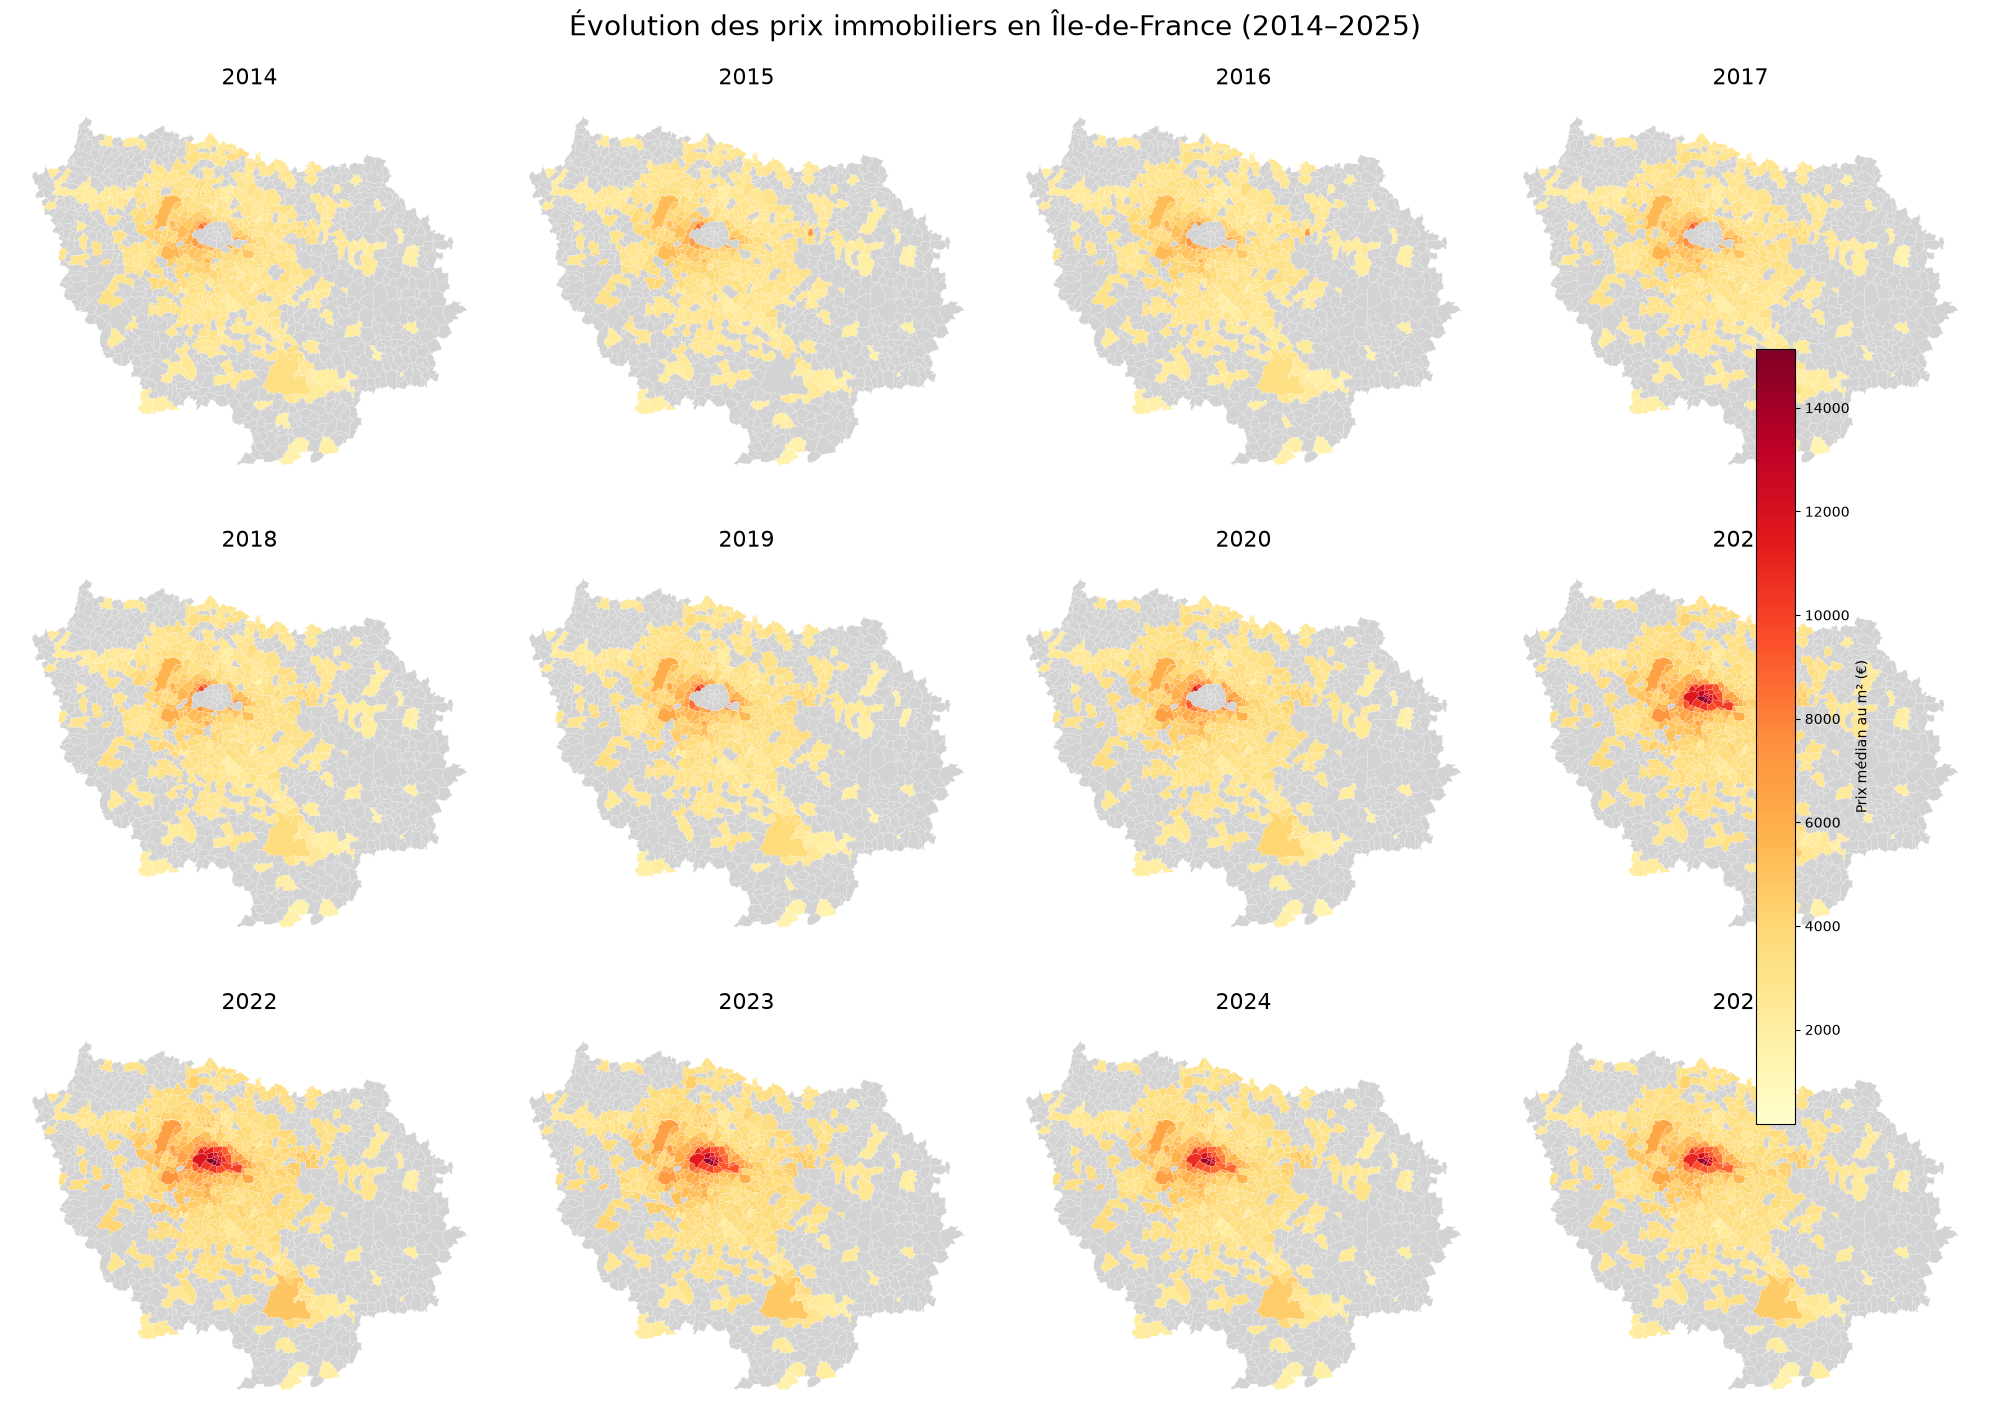

In [39]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))

# Échelle de couleurs commune à toutes les années
vmin = prix[annees].min().min()
vmax = prix[annees].max().max()

for ax, year in zip(axes.flatten(), annees):

    # Données de l'année
    year_data = prix[["code_insee", year]].set_index("code_insee")

    # Jointure avec les contours
    gdf = communes.merge(
        year_data,
        left_on="code",
        right_index=True,
        how="left"
    )

    # Tracer la carte
    gdf.plot(
        column=year,
        cmap="YlOrRd",
        ax=ax,
        vmin=vmin,
        vmax=vmax,
        edgecolor="white",
        linewidth=0.1,
        missing_kwds={"color": "lightgrey"}
    )

    ax.set_title(str(year), fontsize=16, pad=10)
    ax.set_axis_off()

# Ajouter une seule légende commune
sm = plt.cm.ScalarMappable(
    cmap="YlOrRd",
    norm=plt.Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=axes,
    orientation="vertical",
    fraction=0.025,
    pad=0.02,
    label="Prix médian au m² (€)"
)

plt.suptitle(
    "Évolution des prix immobiliers en Île-de-France (2014–2025)",
    fontsize=20,
    y=0.98
)

plt.tight_layout()
plt.show()

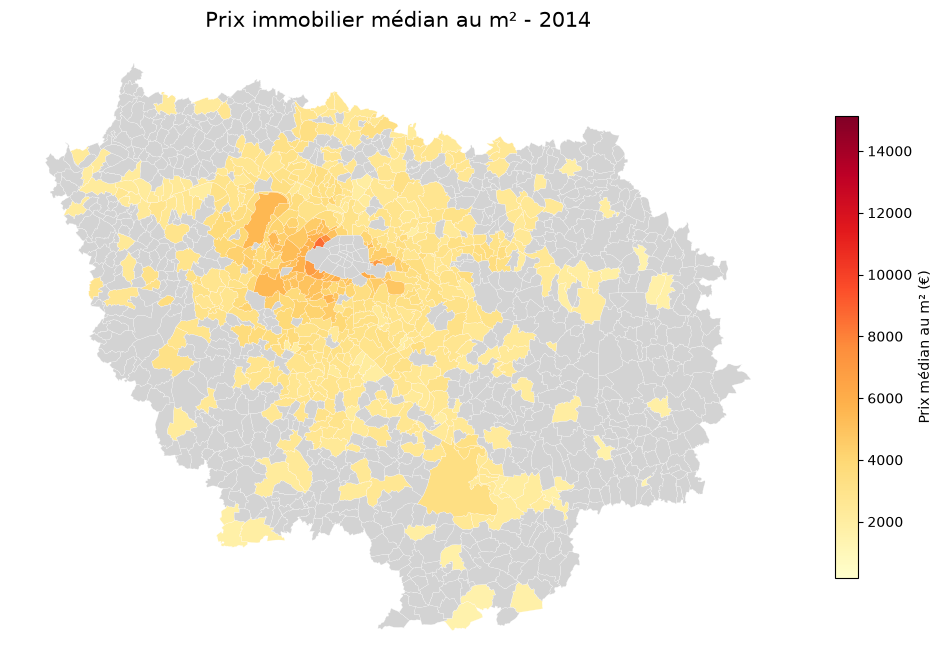

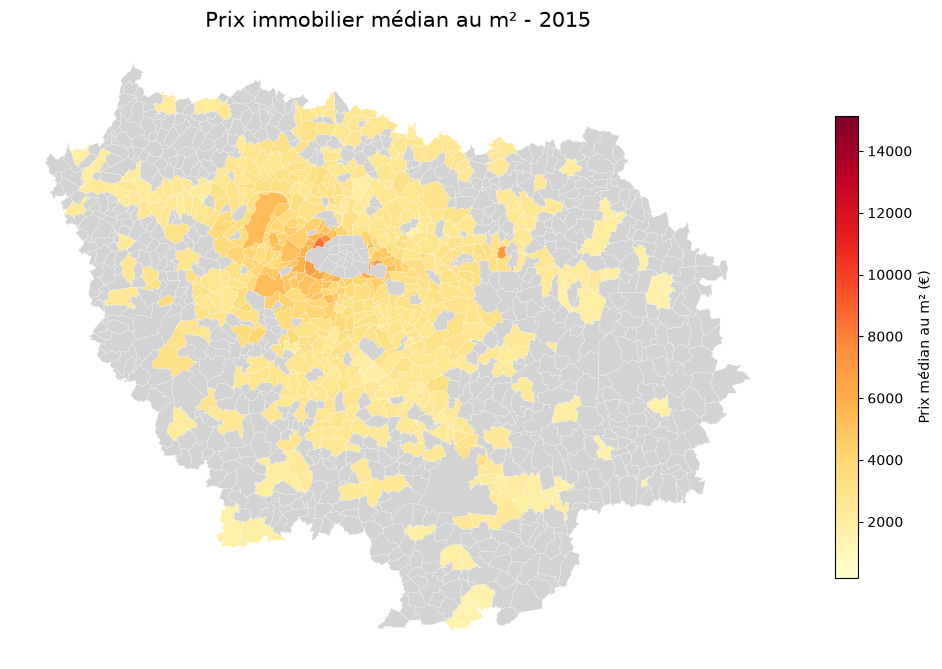

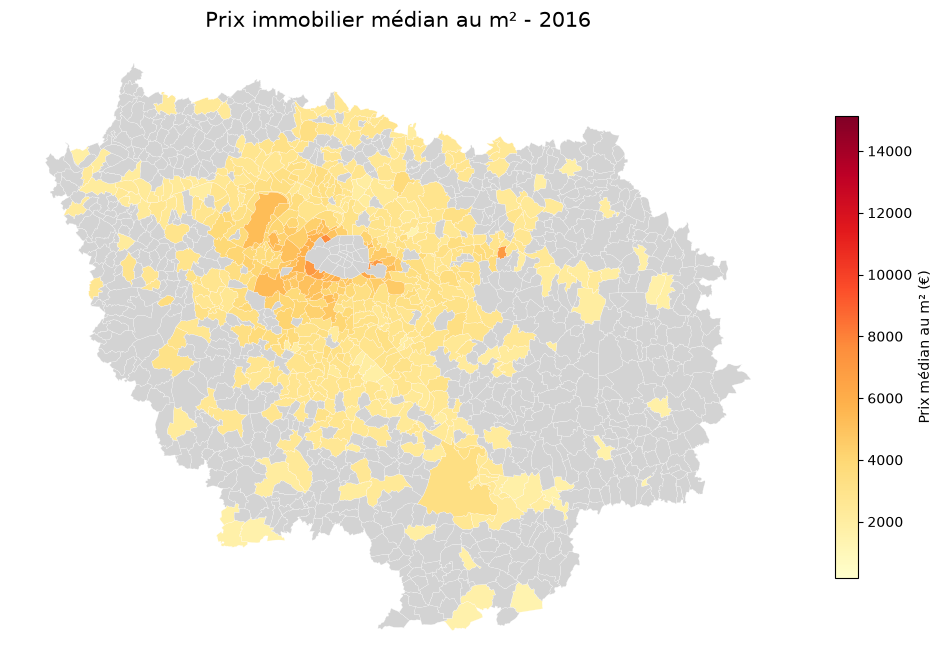

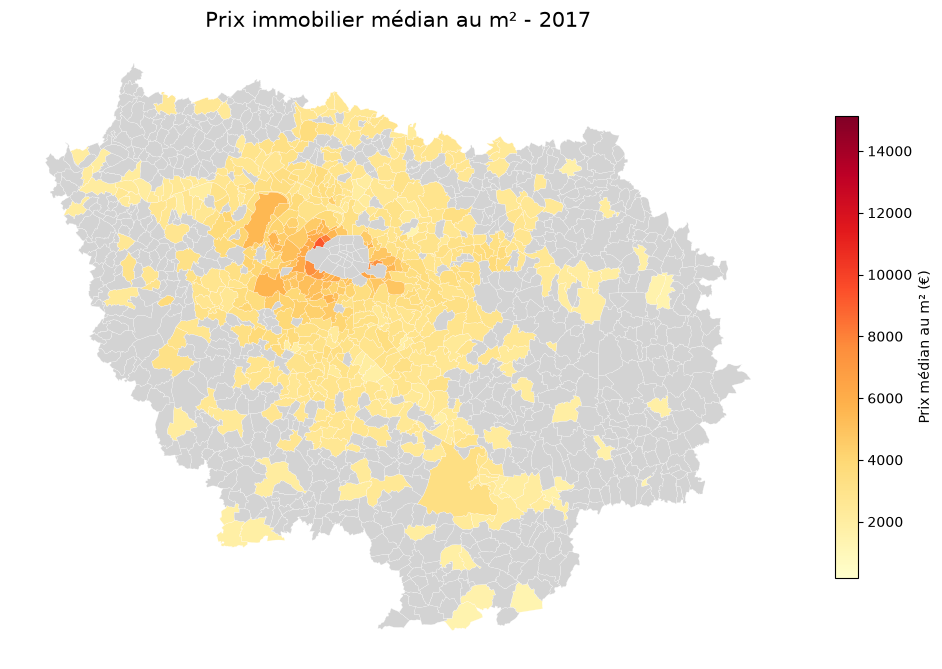

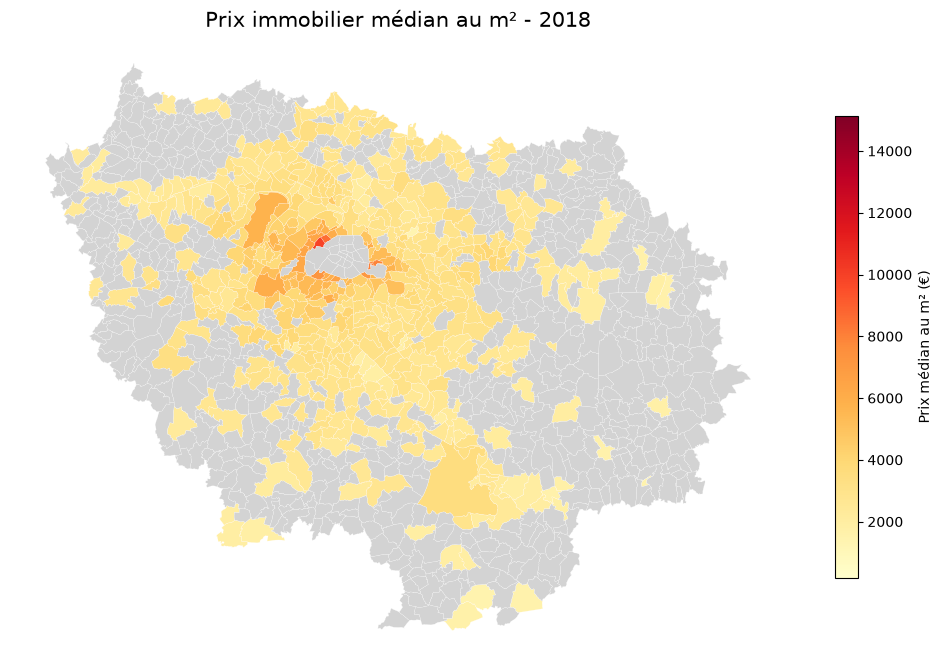

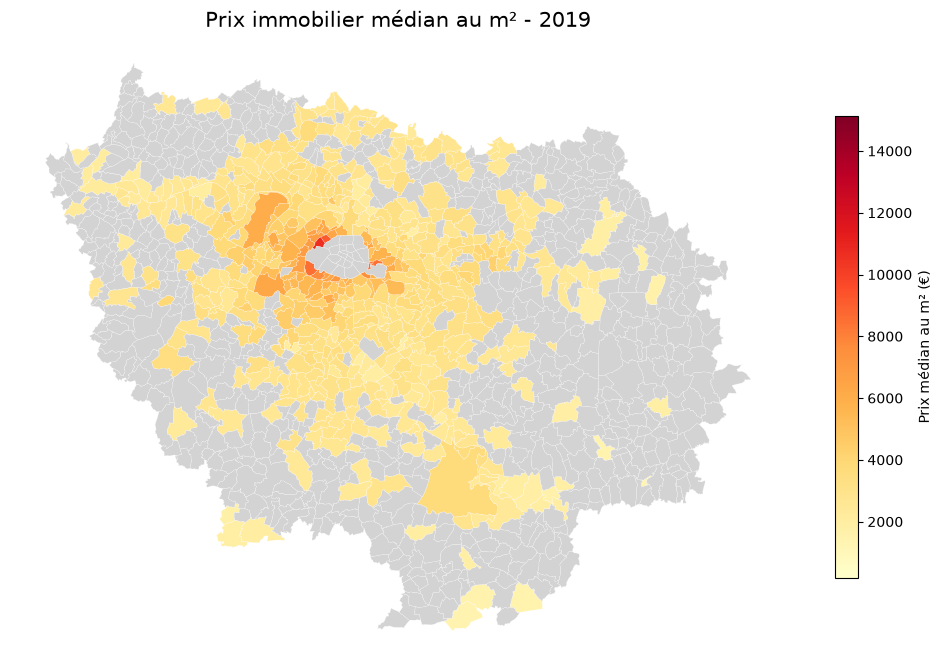

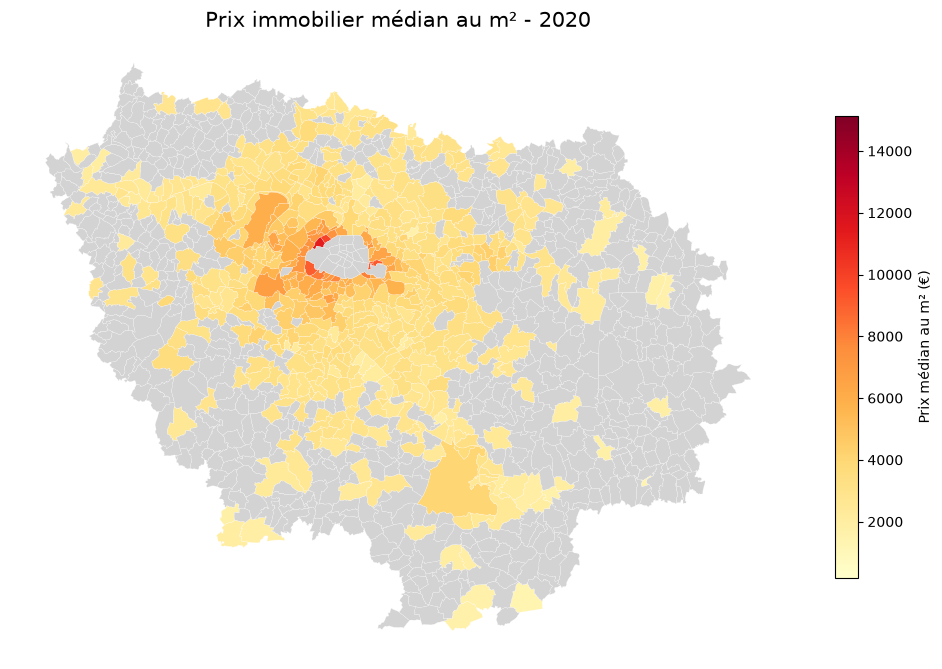

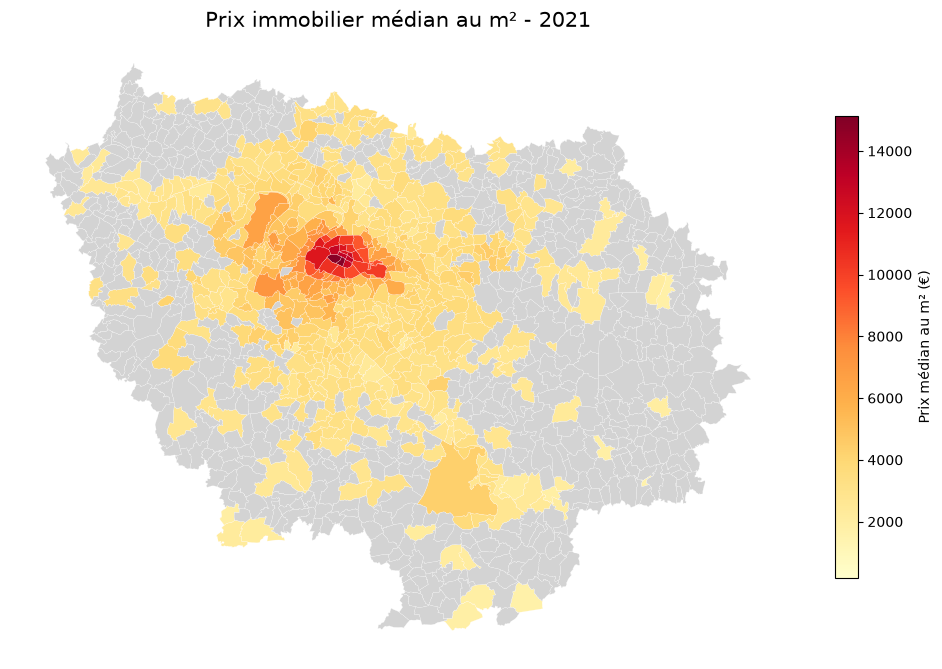

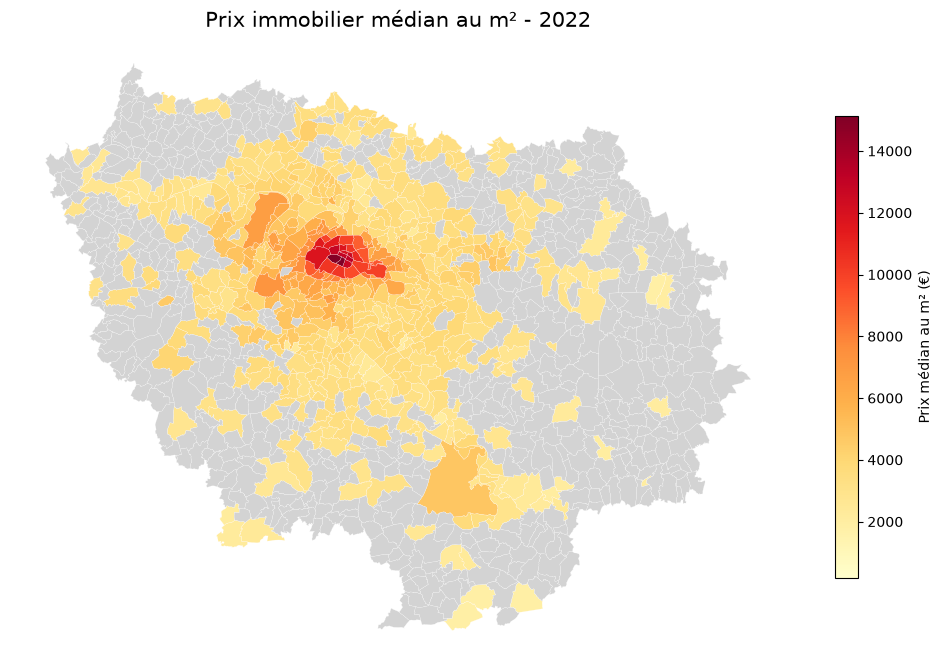

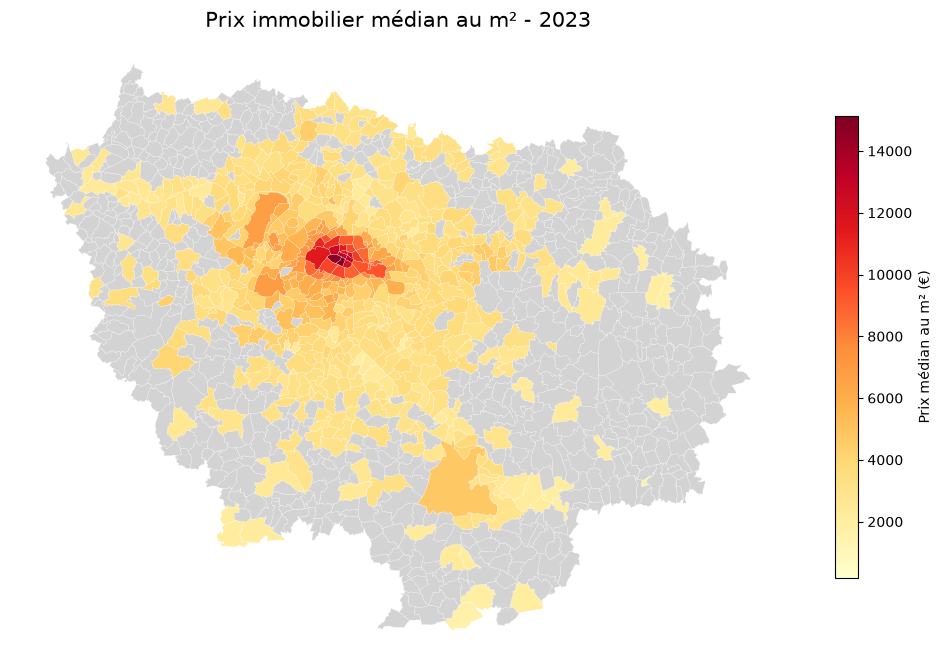

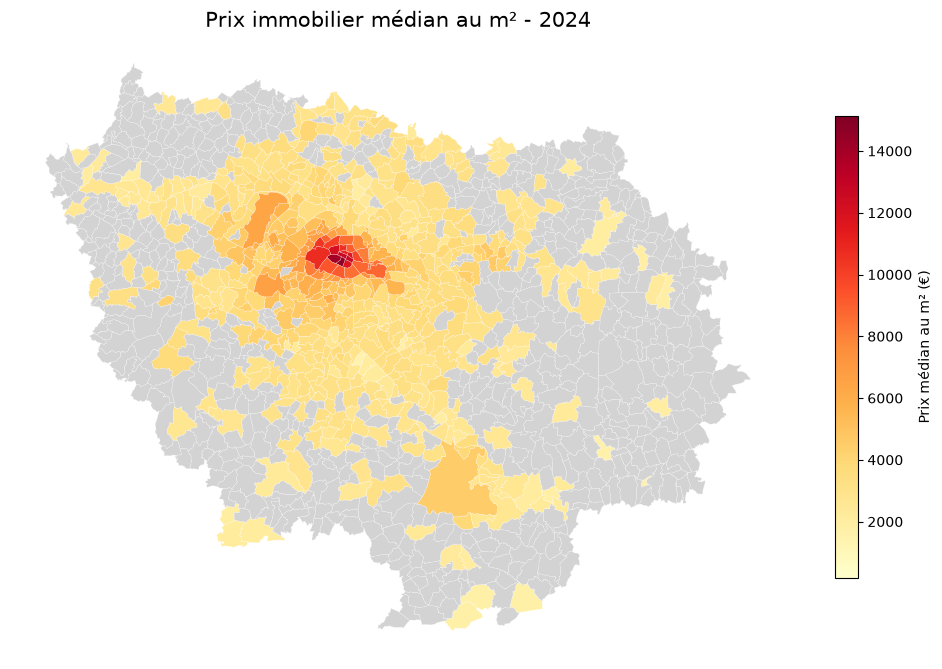

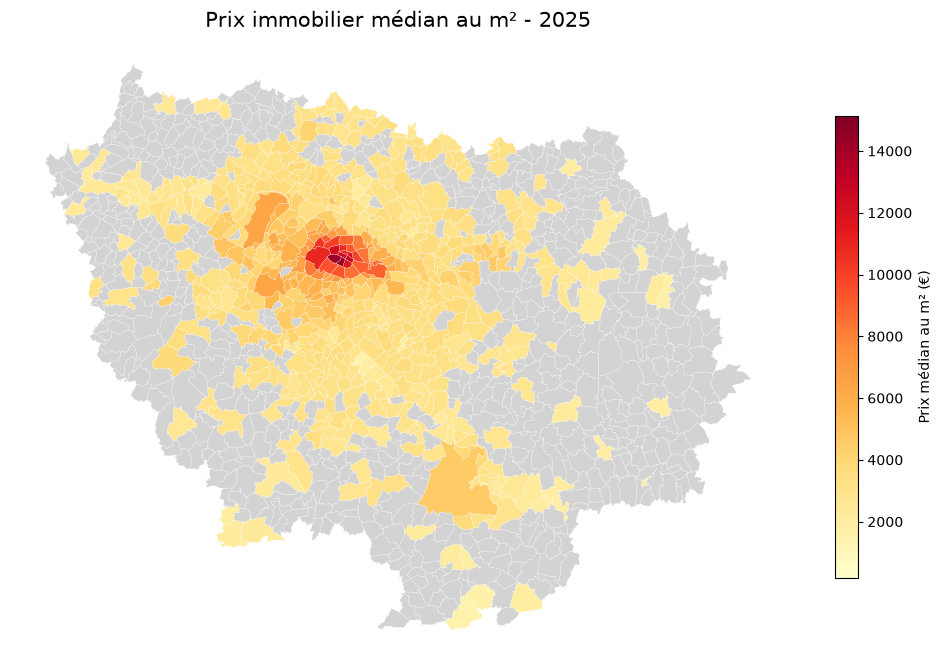

In [25]:
for year in annees:

    # Sélectionner les données de l'année
    year_data = prix[["code_insee", year]].set_index("code_insee")

    # Fusionner avec les contours géographiques
    gdf = communes.merge(
        year_data,
        left_on="code",
        right_index=True,
        how="left"
    )

    # Créer la carte
    fig, ax = plt.subplots(figsize=(10, 8))

    # Afficher les communes selon leur prix au m²
    gdf.plot(
        column=year,
        cmap="YlOrRd",
        ax=ax,
        vmin=vmin,
        vmax=vmax,
        legend=True,
        edgecolor="white",
        linewidth=0.15,
        legend_kwds={
            "label": "Prix médian au m² (€)",
            "shrink": 0.6
        },
        missing_kwds={
            "color": "lightgrey",
            "label": "Données manquantes"
        }
    )

    # Titre et mise en forme
    ax.set_title(f"Prix immobilier médian au m² - {year}", fontsize=15)
    ax.set_axis_off()

    plt.tight_layout()
    plt.show()

In [38]:
test = communes.merge(
    prix[["code_insee", 2023]],
    left_on="code",
    right_on="code_insee",
    how="left"
)

print("Communes avec correspondance INSEE :",
      test["code_insee"].notna().sum())

print("Communes sans correspondance INSEE :",
      test["code_insee"].isna().sum())

print("Communes avec correspondance mais sans prix :",
      test.loc[test["code_insee"].notna(), 2023].isna().sum())

print("Communes avec un prix en 2023 :",
      test[2023].notna().sum())

Communes avec correspondance INSEE : 573
Communes sans correspondance INSEE : 712
Communes avec correspondance mais sans prix : 0
Communes avec un prix en 2023 : 573


In [28]:
# Communes sans correspondance dans Prix_immo
sans_correspondance = test[
    test["code_insee"].isna()
]

# Communes ayant un code INSEE correspondant mais pas de prix
sans_prix = test[
    test["code_insee"].notna() & test[2014].isna()
]

print("Sans correspondance :")
print(sans_correspondance["code"].head(20).tolist())

print("\nAvec correspondance mais sans prix :")
print(sans_prix["code"].head(20).tolist())

Sans correspondance :
['77001', '77002', '77003', '77004', '77006', '77007', '77008', '77009', '77010', '77011', '77012', '77013', '77015', '77016', '77019', '77020', '77021', '77022', '77023', '77024']

Avec correspondance mais sans prix :
['77058', '77122', '77238', '77249', '77255', '77333', '78172', '78206', '78297', '78299', '78367', '91174', '91200', '91340', '91345', '93029', '93030', '94038', '94041', '94052']


In [29]:
# Afficher quelques codes des communes sans correspondance
print("Codes géographiques sans correspondance :")
print(sans_correspondance["code"].head(30).tolist())

print("\nCodes de Prix_immo :")
print(prix["code_insee"].head(30).tolist())

print("\nNombre de codes distincts dans Prix_immo :")
print(prix["code_insee"].nunique())

print("\nNombre de codes distincts dans communes :")
print(communes["code"].nunique())

Codes géographiques sans correspondance :
['77001', '77002', '77003', '77004', '77006', '77007', '77008', '77009', '77010', '77011', '77012', '77013', '77015', '77016', '77019', '77020', '77021', '77022', '77023', '77024', '77025', '77026', '77027', '77029', '77030', '77031', '77032', '77033', '77034', '77035']

Codes de Prix_immo :
['01004', '01007', '01014', '01024', '01025', '01027', '01031', '01032', '01033', '01034', '01043', '01049', '01053', '01071', '01072', '01074', '01089', '01093', '01103', '01105', '01109', '01130', '01135', '01138', '01142', '01143', '01148', '01153', '01157', '01159']

Nombre de codes distincts dans Prix_immo :
5255

Nombre de codes distincts dans communes :
1285


In [30]:
# Codes INSEE des communes géographiques d'IDF
codes_idf = set(communes["code"])

# Codes INSEE de toutes les communes ayant des données immobilières
codes_prix = set(prix["code_insee"])

# Intersection
codes_communs = codes_idf.intersection(codes_prix)

print("Communes en IDF :", len(codes_idf))
print("Communes avec données immobilières en IDF :", len(codes_communs))
print("Communes IDF sans données immobilières :", 
      len(codes_idf - codes_prix))

Communes en IDF : 1285
Communes avec données immobilières en IDF : 573
Communes IDF sans données immobilières : 712


In [31]:
prix_idf = prix[prix["code_insee"].isin(codes_idf)].copy()

print("Communes IDF dans Prix_immo :", len(prix_idf))
print("Communes avec prix en 2014 :", prix_idf[2014].notna().sum())
print("Communes sans prix en 2014 :", prix_idf[2014].isna().sum())

Communes IDF dans Prix_immo : 573
Communes avec prix en 2014 : 530
Communes sans prix en 2014 : 43
